# Toyota Corolla Price Prediction (Multiple Linear Regression)

**Question:** Which car attributes drive the resale price of a used Toyota Corolla, and how well can a linear model predict it?

Dataset: 1,436 used Toyota Corolla listings, 11 columns (price, age in months, kilometres, fuel type, horsepower, automatic, engine cc, doors, cylinders, gears, weight).

Steps: data check, scatter plots against price, dummy encoding, correlation, three linear models with different feature sets, coefficient interpretation, Ridge and Lasso.

## 1. Load and inspect the data

In [1]:
import pandas as pd
import numpy as np

In [2]:
df = pd.read_csv('../data/toyota-corolla.csv')
df.head()

,Price,Age_08_04,KM,Fuel_Type,HP,Automatic,cc,Doors,Cylinders,Gears,Weight
0,13500,23,46986,Diesel,90,0,2000,3,4,5,1165
1,13750,23,72937,Diesel,90,0,2000,3,4,5,1165
2,13950,24,41711,Diesel,90,0,2000,3,4,5,1165
3,14950,26,48000,Diesel,90,0,2000,3,4,5,1165
4,13750,30,38500,Diesel,90,0,2000,3,4,5,1170


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1436 entries, 0 to 1435
Data columns (total 11 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   Price      1436 non-null   int64 
 1   Age_08_04  1436 non-null   int64 
 2   KM         1436 non-null   int64 
 3   Fuel_Type  1436 non-null   object
 4   HP         1436 non-null   int64 
 5   Automatic  1436 non-null   int64 
 6   cc         1436 non-null   int64 
 7   Doors      1436 non-null   int64 
 8   Cylinders  1436 non-null   int64 
 9   Gears      1436 non-null   int64 
 10  Weight     1436 non-null   int64 
dtypes: int64(10), object(1)
memory usage: 123.5+ KB


In [4]:
df.describe()

,Price,Age_08_04,KM,HP,Automatic,cc,Doors,Cylinders,Gears,Weight
count,1436.000000,1436.000000,1436.000000,1436.000000,1436.000000,1436.00000,1436.000000,1436.0,1436.000000,1436.00000
mean,10730.824513,55.947075,68533.259749,101.502089,0.055710,1576.85585,4.033426,4.0,5.026462,1072.45961
std,3626.964585,18.599988,37506.448872,14.981080,0.229441,424.38677,0.952677,0.0,0.188510,52.64112
min,4350.000000,1.000000,1.000000,69.000000,0.000000,1300.00000,2.000000,4.0,3.000000,1000.00000
25%,8450.000000,44.000000,43000.000000,90.000000,0.000000,1400.00000,3.000000,4.0,5.000000,1040.00000
50%,9900.000000,61.000000,63389.500000,110.000000,0.000000,1600.00000,4.000000,4.0,5.000000,1070.00000
75%,11950.000000,70.000000,87020.750000,110.000000,0.000000,1600.00000,5.000000,4.0,5.000000,1085.00000
max,32500.000000,80.000000,243000.000000,192.000000,1.000000,16000.00000,5.000000,4.0,6.000000,1615.00000


In [5]:
df.rename(columns={'Age_08_04': 'Age','cc':'CC'}, inplace=True)

In [6]:
df.head()

,Price,Age,KM,Fuel_Type,HP,Automatic,CC,Doors,Cylinders,Gears,Weight
0,13500,23,46986,Diesel,90,0,2000,3,4,5,1165
1,13750,23,72937,Diesel,90,0,2000,3,4,5,1165
2,13950,24,41711,Diesel,90,0,2000,3,4,5,1165
3,14950,26,48000,Diesel,90,0,2000,3,4,5,1165
4,13750,30,38500,Diesel,90,0,2000,3,4,5,1170


## 2. Relationship of each numeric feature with price

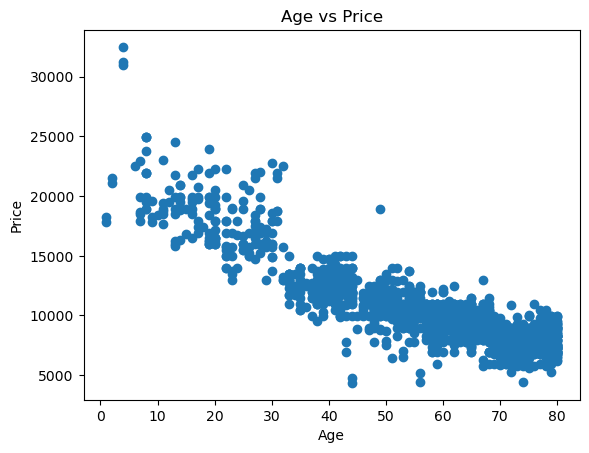

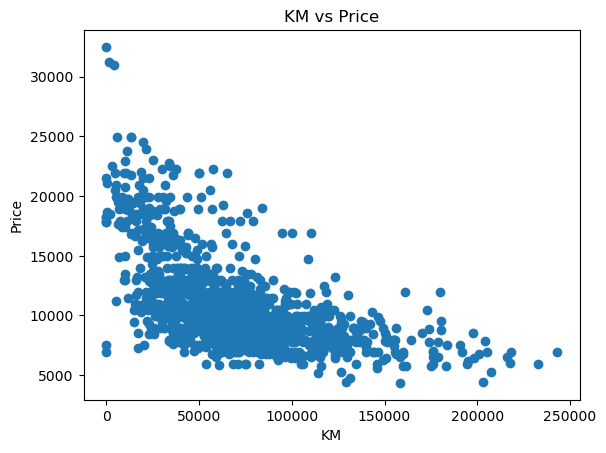

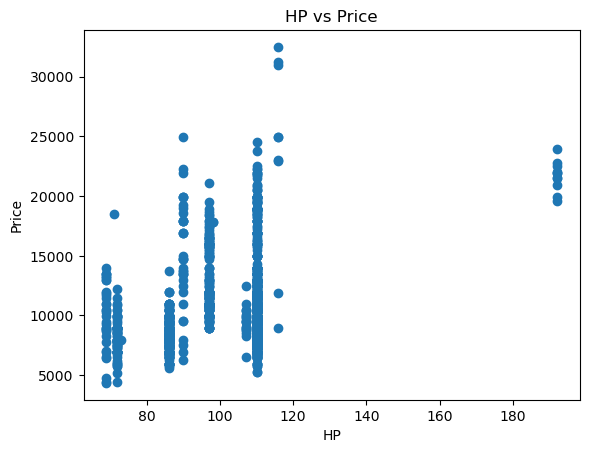

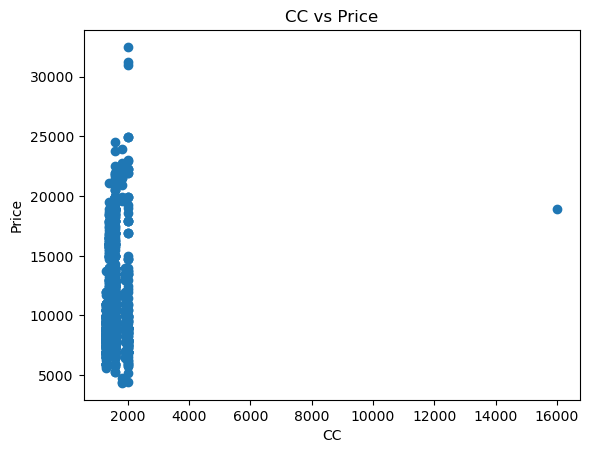

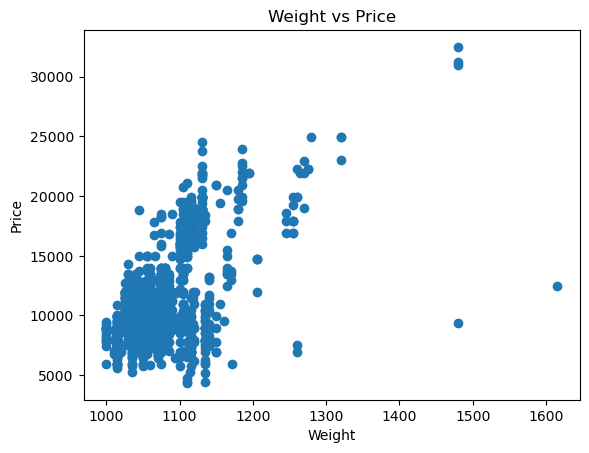

In [7]:
import matplotlib.pyplot as plt

features = ['Age', 'KM', 'HP', 'CC', 'Weight']

for col in features:
    plt.scatter(df[col], df['Price'])
    plt.xlabel(col)
    plt.ylabel('Price')
    plt.title(f"{col} vs Price")
    plt.show()

## 3. Preprocessing: dummy-encode fuel type, check correlation with price, drop constant Cylinders column

In [8]:
df = pd.get_dummies(df, columns=['Fuel_Type'], drop_first=True)

In [9]:
df.corr()['Price'].sort_values(ascending=False)

Price               1.000000
Weight              0.581198
HP                  0.314990
Doors               0.185326
CC                  0.126389
Gears               0.063104
Fuel_Type_Diesel    0.054084
Automatic           0.033081
Fuel_Type_Petrol   -0.038516
KM                 -0.569960
Age                -0.876590
Cylinders                NaN
Name: Price, dtype: float64

In [10]:
df.drop('Cylinders', axis=1, inplace=True)

In [11]:
df.head()

,Price,Age,KM,HP,Automatic,CC,Doors,Gears,Weight,Fuel_Type_Diesel,Fuel_Type_Petrol
0,13500,23,46986,90,0,2000,3,5,1165,True,False
1,13750,23,72937,90,0,2000,3,5,1165,True,False
2,13950,24,41711,90,0,2000,3,5,1165,True,False
3,14950,26,48000,90,0,2000,3,5,1165,True,False
4,13750,30,38500,90,0,2000,3,5,1170,True,False


## Model 1

In [12]:
x = df.drop(['Price'],axis =1)
y = df['Price']

In [13]:
from sklearn.model_selection import train_test_split
x_train , x_test , y_train , y_test = train_test_split(x,y,test_size =0.2, random_state=42)

In [31]:
from sklearn.linear_model import LinearRegression
lr = LinearRegression()
lr.fit(x_train,y_train)


LinearRegression()

In [32]:
y_pred = lr.predict(x_test)

In [33]:
from sklearn.metrics import mean_squared_error, r2_score
rmse1 = np.sqrt(mean_squared_error(y_test, y_pred))
r21 = r2_score(y_test, y_pred)

print("RMSE:", rmse1)
print("R2 Score:", r21)

RMSE: 1484.265415329651
R2 Score: 0.8348888040611083


## Model 2 

In [17]:
# In model 2 I am removing all the weak features in the co relation result like gears, fuel_type, doors

In [18]:
from sklearn.linear_model import LinearRegression
x_train2 = x_train.drop(columns=['Gears', 'Doors', 'Fuel_Type_Diesel', 'Fuel_Type_Petrol'])
x_test2 = x_test.drop(columns=['Gears', 'Doors', 'Fuel_Type_Diesel', 'Fuel_Type_Petrol'])

lr2 = LinearRegression()
lr2.fit(x_train2, y_train)

LinearRegression()

In [19]:
y_pred_2 = lr2.predict(x_test2)

In [20]:
rmse1 = np.sqrt(mean_squared_error(y_test, y_pred_2))
r21 = r2_score(y_test, y_pred_2)

print("RMSE:", rmse1)
print("R2 Score:", r21)

RMSE: 1410.0822641865045
R2 Score: 0.8509807795757859


## Model 3 

In [21]:
# In model 3 let's try to reduce multicolinearity as Age and Km both are highly co-linear and Age being the height weigh removing km 

In [22]:
x_train3 = x_train2.drop(columns=['KM'])
x_test3 = x_test2.drop(columns=['KM'])

lr3 = LinearRegression()
lr3.fit(x_train3,y_train)

LinearRegression()

In [23]:
y_pred_3 = lr3.predict(x_test3)

In [24]:
rmse1 = np.sqrt(mean_squared_error(y_test, y_pred_3))
r21 = r2_score(y_test, y_pred_3)

print("RMSE:", rmse1)
print("R2 Score:", r21)

RMSE: 1488.1827282936767
R2 Score: 0.834016122211436


Model 2 performed the best with the lowest RMSE and highest R² score. Removing weakly correlated features improved model performance significantly. However, removing strongly correlated features like KM in Model 3 reduced performance, indicating that such variables still contain important predictive information despite multicollinearity.

In [35]:
# Coef Interpretation
coef_df = pd.DataFrame({
    "Feature": x_train.columns,
    "Coefficient": lr.coef_
})

print(coef_df)

            Feature  Coefficient
0               Age  -120.830458
1                KM    -0.016231
2                HP    14.039479
3         Automatic   148.830927
4                CC    -0.030372
5             Doors   -60.310974
6             Gears   551.600710
7            Weight    25.884958
8  Fuel_Type_Diesel   -68.548757
9  Fuel_Type_Petrol  1370.808910


Age has a negative coefficient, indicating that older cars tend to have lower prices.<br>
HP has a positive coefficient, meaning cars with higher horsepower generally have higher prices.<br>
Weight has a positive coefficient, suggesting heavier cars are associated with higher prices.<br>
KM has a negative coefficient, indicating that cars driven more kilometers generally have lower prices.<br>

## Ridge Regression

In [25]:
from sklearn.linear_model import Ridge

In [26]:
ridge = Ridge(alpha = 1.0)
ridge.fit(x_train,y_train)

y_pred_ridge = ridge.predict(x_test)

In [27]:
rmse1 = np.sqrt(mean_squared_error(y_test, y_pred_ridge))
r21 = r2_score(y_test, y_pred_ridge)

print("RMSE:", rmse1)
print("R2 Score:", r21)

RMSE: 1483.1541963778864
R2 Score: 0.835135937771234


## Lasso Regrssion

In [28]:
from sklearn.linear_model import Lasso 

In [29]:
lasso = Lasso(alpha = 1.0)
lasso.fit(x_train,y_train)

y_pred_lasso = lasso.predict(x_test)

In [30]:
rmse1 = np.sqrt(mean_squared_error(y_test, y_pred_lasso))
r21 = r2_score(y_test, y_pred_lasso)

print("RMSE:", rmse1)
print("R2 Score:", r21)

RMSE: 1481.6839224634043
R2 Score: 0.8354626403967389


Model 2 performed the best with the lowest RMSE and highest R² score, indicating strong predictive performance. Removing less significant variables improved the model. Ridge and Lasso regression produced similar results, suggesting that multicollinearity was not significantly affecting the model. Lasso also provided feature selection benefits, making the model simpler without sacrificing much accuracy.

## Q1. What is the difference between normalisation and standardisation?

**Normalisation** (min-max scaling) rescales a feature into a fixed range, usually 0 to 1, using (x - min) / (max - min). It keeps the shape of the distribution but is sensitive to outliers, because one extreme value stretches the range.<br>
**Standardisation** (z-score scaling) rescales a feature to mean 0 and standard deviation 1, using (x - mean) / std. It is the usual choice for linear models and regularised regression (Ridge, Lasso), where features need to be on a comparable scale. It is also affected by outliers, but does not force values into a fixed range.<br>
Encoding a category such as Petrol = 0 / Diesel = 1 is neither of these; that is one-hot (dummy) encoding.

## Q2. How can multicollinearity be addressed?

Multicollinearity can be addressed by removing highly correlated variables, using Variance Inflation Factor (VIF) to detect and drop problematic features, applying regularization techniques like Ridge and Lasso, or using dimensionality reduction methods like PCA.